In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
!wget -O sms_spam.zip https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip

!unzip -o sms_spam.zip

--2026-11-12 13:38:00--  https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘sms_spam.zip’

sms_spam.zip            [ <=>                ] 198.65K  1015KB/s    in 0.2s    

2026-11-12 13:38:01 (1015 KB/s) - ‘sms_spam.zip’ saved [203415]

Archive:  sms_spam.zip
  inflating: SMSSpamCollection       
  inflating: readme                  


In [ ]:
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [ ]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print(df["label"].value_counts())


print("\nLabel percentages:")
print(df["label"].value_counts(normalize=True) * 100)

Dataset shape: (5572, 2)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
label
ham     4825
spam     747
Name: count, dtype: int64

Label percentages:
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


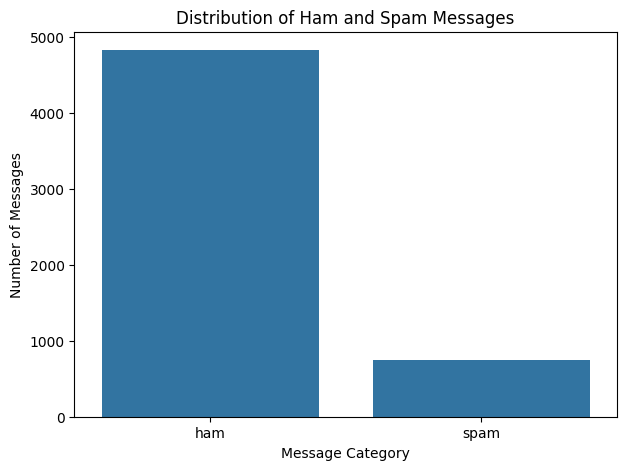

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="label")

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

In [ ]:
print("HAM MESSAGE:")
print(df[df["label"] == "ham"]["message"].iloc[0])

print("\nSPAM MESSAGE:")
print(df[df["label"] == "spam"]["message"].iloc[0])


print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())


HAM MESSAGE:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

SPAM MESSAGE:
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Missing values:
label      0
message    0
dtype: int64

Duplicate rows:
403
Missing values:
label      0
message    0
dtype: int64

Duplicate rows:
403


In [ ]:
# Check dataset size before removing duplicates
print("Before cleaning:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

# Reset row numbering
df = df.reset_index(drop=True)

# Check dataset size after removing duplicates
print("After cleaning:", df.shape)

# Check remaining duplicates
print("Remaining duplicates:", df.duplicated().sum())


print("Missing values:")
print(df.isnull().sum())

df["message"] = df["message"].str.lower()

print(df["message"].head())


import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text

df["message"] = df["message"].apply(clean_text)

print(df["message"].head())


print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

df.to_csv("cleaned_sms_spam.csv", index=False)

print("Cleaned dataset saved successfully!")

# Input features
X = df["message"]

# Target labels
y = df["label"]

print("Input features:")
print(X.head())

print("\nTarget labels:")
print(y.head())

from sklearn.feature_extraction.text import TfidfVectorizer

print("TF-IDF imported successfully!")

tfidf = TfidfVectorizer(
    max_features=3000,
    stop_words="english"
)

X_tfidf = tfidf.fit_transform(X)

print("TF-IDF transformation completed!")
print("Feature matrix shape:", X_tfidf.shape)

feature_names = tfidf.get_feature_names_out()

print("First 30 vocabulary words:")
print(feature_names[:30])

message_index = 0

print("Original message:")
print(X.iloc[message_index])

print("\nNumerical representation:")
print(X_tfidf[message_index].toarray())

import pandas as pd

message_vector = X_tfidf[message_index].toarray()[0]

word_weights = pd.DataFrame({
    "word": feature_names,
    "tfidf_score": message_vector
})

word_weights = word_weights[word_weights["tfidf_score"] > 0]

print(word_weights.sort_values(
    by="tfidf_score",
    ascending=False
))

from sklearn.model_selection import train_test_split

print("train_test_split imported successfully!")

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset splitting completed!")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("Training label distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting label distribution:")
print(y_test.value_counts(normalize=True) * 100)

X_tfidf = tfidf.fit_transform(X)

# Split the original text messages
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Learn vocabulary and IDF weights from training messages only
tfidf = TfidfVectorizer(
    max_features=3000,
    stop_words="english"
)

X_train = tfidf.fit_transform(X_train_text)

# Transform test messages without fitting again
X_test = tfidf.transform(X_test_text)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

from sklearn.naive_bayes import MultinomialNB

print("Naive Bayes imported successfully!")

model = MultinomialNB()

print("Naive Bayes model created!")

model.fit(X_train, y_train)

print("Model training completed!")

y_pred = model.predict(X_test)

print("Predictions completed!")

print("\nFirst 10 predictions:")
print(y_pred[:10])

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results.head(15))


import joblib

joblib.dump(model, "sms_spam_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectoriser saved successfully!")

Before cleaning: (5157, 2)
After cleaning: (5157, 2)
Remaining duplicates: 0
Missing values:
label      0
message    0
dtype: int64
0    go until jurong point, crazy.. available only ...
1                        ok lar... joking wif u oni...
2    free entry in 2 a wkly comp to win fa cup fina...
3    u dun say so early hor... u c already then say...
4    nah i don't think he goes to usf, he lives aro...
Name: message, dtype: object
0    go until jurong point, crazy.. available only ...
1                        ok lar... joking wif u oni...
2    free entry in 2 a wkly comp to win fa cup fina...
3    u dun say so early hor... u c already then say...
4    nah i don't think he goes to usf, he lives aro...
Name: message, dtype: object
Final dataset shape: (5157, 2)

Missing values:
label      0
message    0
dtype: int64

Duplicate rows:
0

Label distribution:
label
ham     4515
spam     642
Name: count, dtype: int64
Cleaned dataset saved successfully!
Input features:
0    go until jurong po

Evaluation metrics imported successfully!
Model Accuracy: 97.38 %
Precision: 100.0 %
Recall: 78.91 %
F1-score: 88.21 %
              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       904
        spam       1.00      0.79      0.88       128

    accuracy                           0.97      1032
   macro avg       0.99      0.89      0.93      1032
weighted avg       0.97      0.97      0.97      1032

[[904   0]
 [ 27 101]]


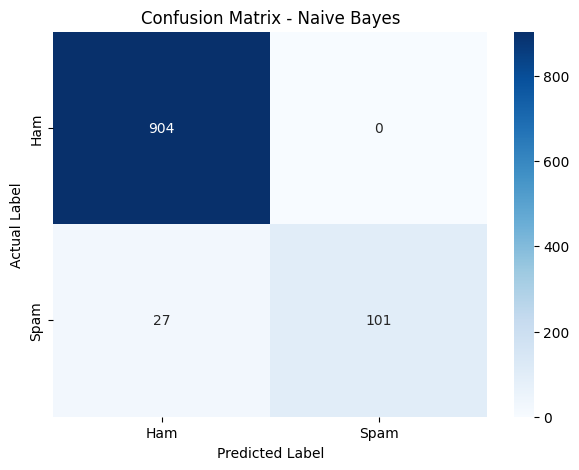

      Metric     Score
0   Accuracy  0.973837
1  Precision  1.000000
2     Recall  0.789062
3   F1-score  0.882096
Logistic Regression imported successfully!
Logistic Regression model created!
Logistic Regression training completed!
Predictions completed!
First 10 predictions:
['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']
LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 96.22 %
Precision: 98.9 %
Recall: 70.31 %
F1-score: 82.19 %
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       904
        spam       0.99      0.70      0.82       128

    accuracy                           0.96      1032
   macro avg       0.97      0.85      0.90      1032
weighted avg       0.96      0.96      0.96      1032



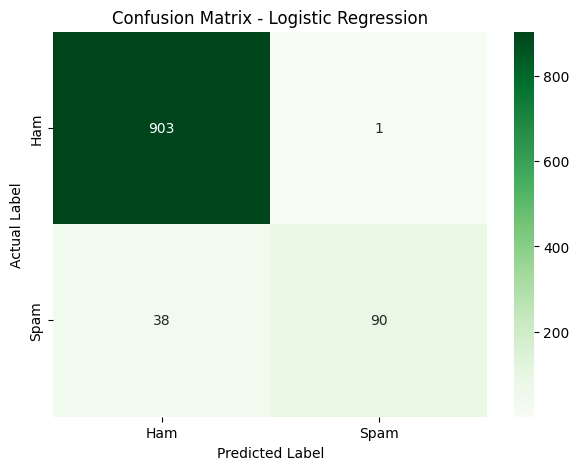

      Metric  Naive Bayes  Logistic Regression
0   Accuracy       0.9738               0.9622
1  Precision       1.0000               0.9890
2     Recall       0.7891               0.7031
3   F1-score       0.8821               0.8219


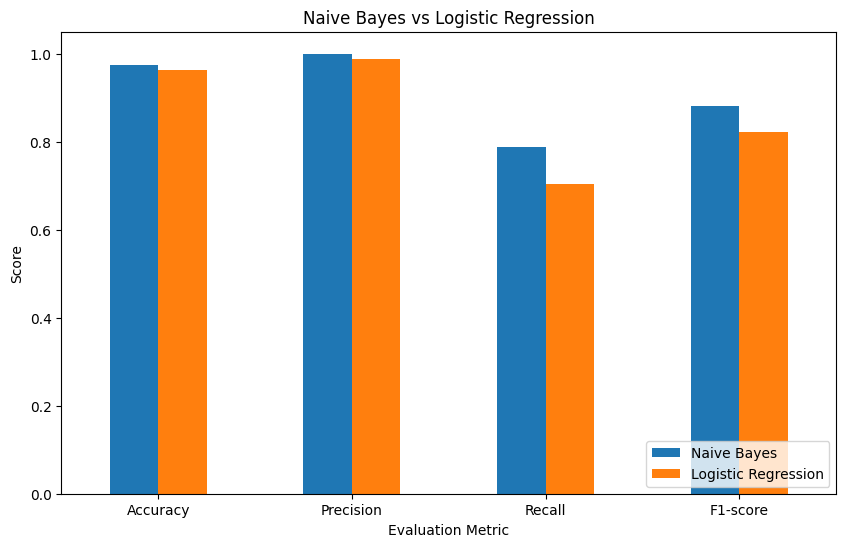

Balanced Logistic Regression trained!
BALANCED LOGISTIC REGRESSION
----------------------------
Accuracy: 97.97 %
Precision: 90.84 %
Recall: 92.97 %
F1-score: 91.89 %
[[892  12]
 [  9 119]]


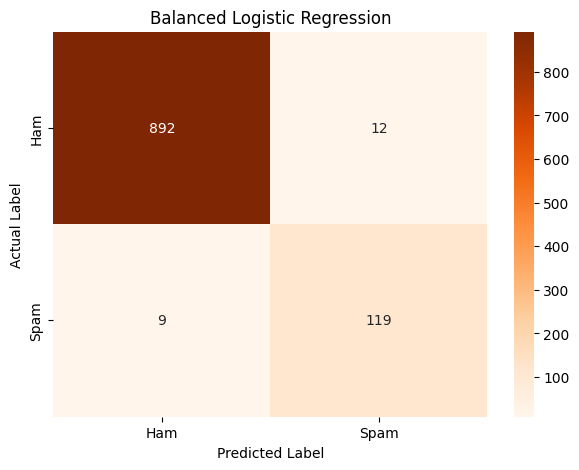

Complement Naive Bayes training completed!
COMPLEMENT NAIVE BAYES
----------------------
Accuracy: 94.96 %
Precision: 72.89 %
Recall: 94.53 %
F1-score: 82.31 %
                          Model  Accuracy  Precision  Recall  F1-score
0       Multinomial Naive Bayes    0.9738     1.0000  0.7891    0.8821
1           Logistic Regression    0.9622     0.9890  0.7031    0.8219
2  Balanced Logistic Regression    0.9797     0.9084  0.9297    0.9189
3        Complement Naive Bayes    0.9496     0.7289  0.9453    0.8231
Best model and vectoriser saved successfully!
Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Confidence: 94.86 %
Message: Hey, are we still meeting tomorrow?
Prediction: HAM
Confidence: 94.44 %
Enter an SMS message: Congratulations! You have won a free prize. Call now!
Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Confidence: 94.86 %


Textarea(value='', description='Message:', layout=Layout(height='100px', width='100%'), placeholder='Enter an …

Button(button_style='success', description='Check Message', style=ButtonStyle())

Output()

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Confidence: 94.86 %


'spam'

In [78]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Evaluation metrics imported successfully!")

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

precision = precision_score(
    y_test,
    y_pred,
    pos_label="spam"
)

print("Precision:", round(precision * 100, 2), "%")

recall = recall_score(
    y_test,
    y_pred,
    pos_label="spam"
)

print("Recall:", round(recall * 100, 2), "%")

f1 = f1_score(
    y_test,
    y_pred,
    pos_label="spam"
)

print("F1-score:", round(f1 * 100, 2), "%")

print(classification_report(y_test, y_pred))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix - Naive Bayes")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

evaluation_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

print(evaluation_results)

evaluation_results.to_csv(
    "naive_bayes_evaluation.csv",
    index=False
)

from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully!")

lr_model = LogisticRegression(max_iter=1000)

print("Logistic Regression model created!")

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

lr_pred = lr_model.predict(X_test)

print("Predictions completed!")

print("First 10 predictions:")
print(lr_pred[:10])

lr_accuracy = accuracy_score(y_test, lr_pred)

lr_precision = precision_score(
    y_test, lr_pred, pos_label="spam"
)

lr_recall = recall_score(
    y_test, lr_pred, pos_label="spam"
)

lr_f1 = f1_score(
    y_test, lr_pred, pos_label="spam"
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Precision:", round(lr_precision * 100, 2), "%")
print("Recall:", round(lr_recall * 100, 2), "%")
print("F1-score:", round(lr_f1 * 100, 2), "%")

print(classification_report(y_test, lr_pred))
lr_cm = confusion_matrix(
    y_test,
    lr_pred,
    labels=["ham", "spam"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix - Logistic Regression")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Naive Bayes": [
        accuracy,
        precision,
        recall,
        f1
    ],
    "Logistic Regression": [
        lr_accuracy,
        lr_precision,
        lr_recall,
        lr_f1
    ]
})

print(comparison.round(4))

comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("Naive Bayes vs Logistic Regression")

plt.ylabel("Score")

plt.xlabel("Evaluation Metric")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

balanced_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_lr.fit(X_train, y_train)

balanced_lr_pred = balanced_lr.predict(X_test)

print("Balanced Logistic Regression trained!")

balanced_accuracy = accuracy_score(y_test, balanced_lr_pred)

balanced_precision = precision_score(
    y_test, balanced_lr_pred, pos_label="spam"
)

balanced_recall = recall_score(
    y_test, balanced_lr_pred, pos_label="spam"
)

balanced_f1 = f1_score(
    y_test, balanced_lr_pred, pos_label="spam"
)

print("BALANCED LOGISTIC REGRESSION")
print("----------------------------")
print("Accuracy:", round(balanced_accuracy * 100, 2), "%")
print("Precision:", round(balanced_precision * 100, 2), "%")
print("Recall:", round(balanced_recall * 100, 2), "%")
print("F1-score:", round(balanced_f1 * 100, 2), "%")

balanced_cm = confusion_matrix(
    y_test,
    balanced_lr_pred,
    labels=["ham", "spam"]
)

print(balanced_cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    balanced_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Balanced Logistic Regression")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

from sklearn.naive_bayes import ComplementNB

cnb_model = ComplementNB()

cnb_model.fit(X_train, y_train)

cnb_pred = cnb_model.predict(X_test)

print("Complement Naive Bayes training completed!")

cnb_accuracy = accuracy_score(y_test, cnb_pred)

cnb_precision = precision_score(
    y_test, cnb_pred, pos_label="spam"
)

cnb_recall = recall_score(
    y_test, cnb_pred, pos_label="spam"
)

cnb_f1 = f1_score(
    y_test, cnb_pred, pos_label="spam"
)

print("COMPLEMENT NAIVE BAYES")
print("----------------------")
print("Accuracy:", round(cnb_accuracy * 100, 2), "%")
print("Precision:", round(cnb_precision * 100, 2), "%")
print("Recall:", round(cnb_recall * 100, 2), "%")
print("F1-score:", round(cnb_f1 * 100, 2), "%")

final_comparison = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression",
        "Balanced Logistic Regression",
        "Complement Naive Bayes"
    ],
    "Accuracy": [
        accuracy,
        lr_accuracy,
        balanced_accuracy,
        cnb_accuracy
    ],
    "Precision": [
        precision,
        lr_precision,
        balanced_precision,
        cnb_precision
    ],
    "Recall": [
        recall,
        lr_recall,
        balanced_recall,
        cnb_recall
    ],
    "F1-score": [
        f1,
        lr_f1,
        balanced_f1,
        cnb_f1
    ]
})

print(final_comparison.round(4))

import joblib

# Save the best-performing model
joblib.dump(balanced_lr, "best_sms_spam_model.pkl")

# Save the fitted TF-IDF vectoriser
joblib.dump(tfidf, "best_tfidf_vectorizer.pkl")

print("Best model and vectoriser saved successfully!")

def predict_sms(message):

    # Clean the input message
    cleaned_message = clean_text(message)

    # Convert text into TF-IDF features
    message_vector = tfidf.transform([cleaned_message])

    # Predict the message category
    prediction = balanced_lr.predict(message_vector)[0]

    # Get prediction probabilities
    probabilities = balanced_lr.predict_proba(message_vector)[0]

    # Find the probability of the predicted class
    classes = list(balanced_lr.classes_)
    confidence = probabilities[classes.index(prediction)] * 100

    # Display result
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print("Confidence:", round(confidence, 2), "%")

    return prediction

spam_message = "Congratulations! You have won a free prize. Call now!"

predict_sms(spam_message)

ham_message = "Hey, are we still meeting tomorrow?"

predict_sms(ham_message)

my_message = input("Enter an SMS message: ")

predict_sms(my_message)

import ipywidgets as widgets
from IPython.display import display, clear_output

message_input = widgets.Textarea(
    placeholder="Enter an SMS message here...",
    description="Message:",
    layout=widgets.Layout(width="100%", height="100px")
)

predict_button = widgets.Button(
    description="Check Message",
    button_style="success"
)

output = widgets.Output()

def on_predict_clicked(button):

    with output:
        clear_output()

        if not message_input.value.strip():
            print("Please enter a message.")
            return

        predict_sms(message_input.value)

predict_button.on_click(on_predict_clicked)

display(message_input, predict_button, output)

test_message = "Congratulations! You have won a free prize. Call now!"
predict_sms(test_message)